# Deep Learning for Credit Card Fraud Detection
## Comparative Evaluation of Deep Learning Architectures under Extreme Class Imbalance
**Course**: ICT-4442 Deep Learning Project, School of Computer Engineering, MIT Manipal  
**Student**: Priyansh Nandan (Reg. No. 230953450)  
**Project Role**: Common Preprocessing Pipeline, Temporal Integrity Verification & Attention-Based Tabular Autoencoder  

---
### Executive Summary & Central Research Objective
Credit card transaction streams exhibit **extreme class imbalance** (in this benchmark, fraud occurs in only $\approx 0.17\%$ of total transactions, and $0.1217\%$ on the chronologically held-out test partition). Under such conditions:
1. Traditional metrics like **Accuracy** and **ROC-AUC** produce severe illusions of model competence.
2. The primary research question is:
   > *"What is the detection trade-off between supervised classification (MLP Baseline, 1-D CNN) and unsupervised reconstruction-based anomaly detection (Attention Autoencoder) in terms of precision achieved at comparable levels of recall?"*

This notebook provides a complete interactive walk-through of the **metrics that matter**, the mathematical principles behind evaluation, comparative performance plots, confusion matrices, error analyses, and architectural trade-offs.


In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Project paths
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
LOGS_DIR = PROJECT_ROOT / "outputs" / "logs"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Publication-grade plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 15,
    "figure.dpi": 130,
})

# Standard architectural color palette across all plots
COLOR_MAP = {
    "Attention Autoencoder": "#1f77b4",  # Steel Blue
    "MLP Baseline": "#ff7f0e",           # Vivid Orange
    "1-D CNN": "#2ca02c",                # Forest Green
    "Random Baseline": "#7f7f7f",        # Neutral Gray
}

print("Environment initialized successfully.")
print(f"Metrics Directory: {METRICS_DIR}")
print(f"Available Files: {[f.name for f in METRICS_DIR.glob('*') if not f.name.startswith('.')]}")


Environment initialized successfully.
Metrics Directory: /Users/priyanshnandan/Documents/DL/CreditCardFraudDL/outputs/metrics
Available Files: ['attention_autoencoder_metrics.json', 'model_comparison_entry.json', 'mlp_metrics.json', 'error_analysis_summary.json', 'test_predictions.npz', 'comparison_table.md', 'comparative_roc_curves.png', 'consolidated_model_comparison.json', 'cnn1d_metrics.json', 'comparative_pr_curves.png', 'mlp_test_predictions.npz']


---
## 1. Data Ingestion, Integrity & The Chronological Split

### Why Random K-Fold Splits Fail in Fraud Detection
In credit card transaction streams, transactions are sequentially ordered in time. A random shuffle or standard K-fold CV leaks future fraud patterns into past training batches (**lookahead leakage**). 

To ensure rigorous financial integrity:
* **Strict Chronological Splitting**:
  * **Train Set (70%)**: First $\approx 37$ hours ($199,364$ transactions).
  * **Validation Set (15%)**: Next $\approx 5.5$ hours ($42,721$ transactions) — strictly for hyperparameter tuning & threshold selection.
  * **Held-Out Test Set (15%)**: Final $\approx 5.5$ hours ($42,722$ transactions, $52$ frauds) — evaluated **once** with frozen thresholds.
* **Leakage-Free Feature Scaling**:
  * `RobustScaler` (median & interquartile range scaling) is fitted **strictly on the training partition** and applied to validation and test data.
* **Unsupervised Manifold Isolation**:
  * For the Attention Autoencoder, all $384$ frauds in the training split were **withheld**. The autoencoder was trained on $198,980$ purely legitimate transactions.


In [2]:
# Load partition statistics and consolidated metrics
comparison_json_path = METRICS_DIR / "consolidated_model_comparison.json"
with open(comparison_json_path, "r") as f:
    comparison_data = json.load(f)

test_info = comparison_data["dataset_split"]
total_test = test_info["test_sample_count"]
fraud_test = test_info["test_fraud_count"]
legit_test = total_test - fraud_test
base_rate = test_info["test_fraud_percentage"]

print("=" * 65)
print("HELD-OUT TEST SET COMPOSITION (Strict Chronological Partition)")
print("=" * 65)
print(f"Total Transactions:        {total_test:,}")
print(f"Legitimate Transactions:   {legit_test:,} ({100 - base_rate:.4f}%)")
print(f"Fraudulent Transactions:   {fraud_test:,} ({base_rate:.4f}%)")
print(f"Class Imbalance Ratio:     1 fraud per {legit_test // fraud_test:,} legitimate transactions")
print(f"Random Guessing Baseline:  P = {fraud_test}/{total_test} = {fraud_test/total_test:.6f} ({base_rate:.4f}%)")
print("=" * 65)


HELD-OUT TEST SET COMPOSITION (Strict Chronological Partition)
Total Transactions:        42,722
Legitimate Transactions:   42,670 (99.8783%)
Fraudulent Transactions:   52 (0.1217%)
Class Imbalance Ratio:     1 fraud per 820 legitimate transactions
Random Guessing Baseline:  P = 52/42722 = 0.001217 (0.1217%)


---
## 2. The Metrics That Matter: Deconstructing Misleading Indicators

In extreme class imbalance ($0.12\%$ fraud rate), standard evaluation metrics lead to dangerous conclusions:

### 1. The Accuracy Paradox
A trivial model that predicts **every single transaction is legitimate** achieves:
$$\text{Accuracy} = \frac{42,670}{42,722} = 99.8783\% \approx \mathbf{99.88\%}$$
While having $99.88\%$ accuracy, it catches **$0$ frauds** and causes total financial loss.

### 2. The ROC-AUC Illusion
Receiver Operating Characteristic (ROC) plots **True Positive Rate (Recall)** against **False Positive Rate (FPR)**:
$$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$
Because $\text{TN} = 42,670$ is massive, even generating $100$ false alarms yields:
$$\text{FPR} = \frac{100}{100 + 42,670} = 0.00234 \quad (0.23\%)$$
This tiny FPR keeps the ROC curve pressed firmly against the top-left corner, yielding deceptively high scores ($>0.90$) for models that actually flood human fraud analysts with false alarms.

### 3. The Definitive Gold Standard: PR-AUC (Precision-Recall AUC)
Precision-Recall curves plot **Precision** vs **Recall**:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}, \qquad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
* Notice that **True Negatives (TN) do not appear** in either formula!
* PR-AUC directly measures how many of the flagged transactions are truly fraudulent, without being diluted by the millions of normal card swipes.
* The random guessing baseline is **$P = 0.0012$ ($0.12\%$)**, making any PR-AUC score a direct measure of signal enrichment over random chance.


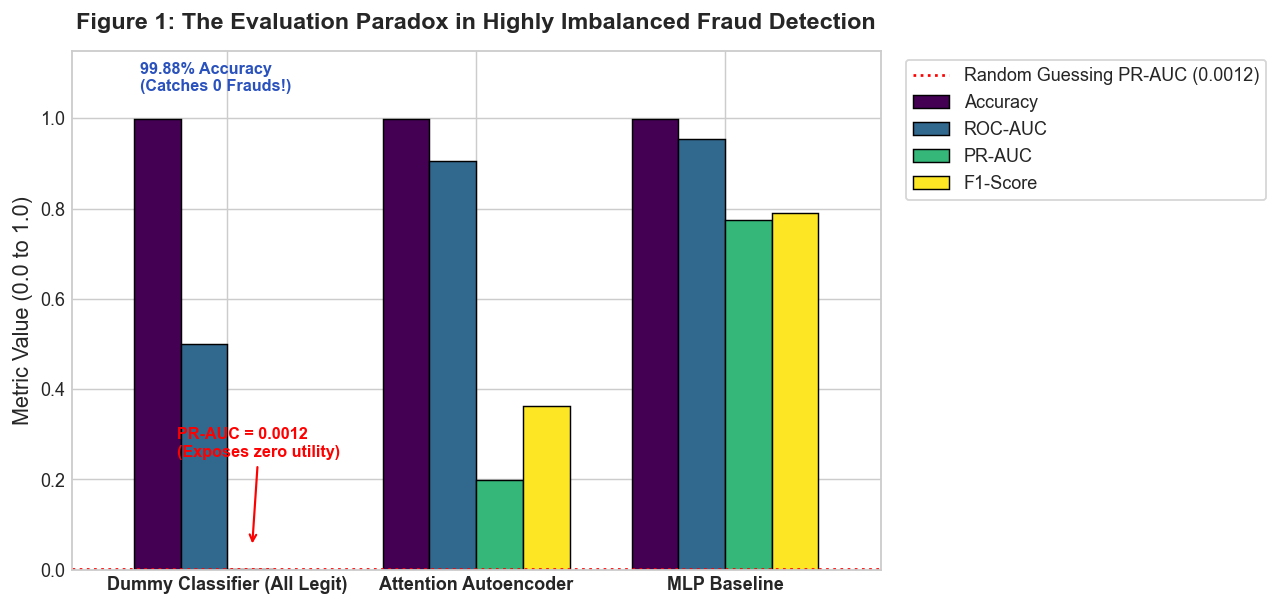

In [3]:
# Demonstrate why Accuracy and ROC-AUC flatter while PR-AUC reveals truth
dummy_metrics = {"Accuracy": 0.99878, "ROC-AUC": 0.5000, "PR-AUC": 0.001217, "F1-Score": 0.0000}
ae_metrics = {"Accuracy": 0.99827, "ROC-AUC": 0.9050, "PR-AUC": 0.1978, "F1-Score": 0.3621}
mlp_metrics = {"Accuracy": 0.99958, "ROC-AUC": 0.9547, "PR-AUC": 0.7751, "F1-Score": 0.7907}

df_paradox = pd.DataFrame([dummy_metrics, ae_metrics, mlp_metrics],
                          index=["Dummy Classifier (All Legit)", "Attention Autoencoder", "MLP Baseline"])

fig, ax = plt.subplots(figsize=(10, 4.8))
df_paradox.plot(kind="bar", ax=ax, colormap="viridis", width=0.75, edgecolor="black", linewidth=0.8)

ax.set_title("Figure 1: The Evaluation Paradox in Highly Imbalanced Fraud Detection", pad=12, fontweight="bold")
ax.set_ylabel("Metric Value (0.0 to 1.0)")
ax.set_ylim(0, 1.15)
ax.axhline(0.001217, color="red", linestyle=":", linewidth=1.5, label="Random Guessing PR-AUC (0.0012)")
plt.xticks(rotation=0, fontweight="bold")
ax.legend(frameon=True, facecolor="white", loc="upper left", bbox_to_anchor=(1.02, 1))

# Annotate the dummy accuracy vs PR-AUC contrast
ax.annotate("99.88% Accuracy\n(Catches 0 Frauds!)",
            xy=(0 - 0.28, 1.0), xytext=(0 - 0.35, 1.06),
            fontweight="bold", color="#2a52be", fontsize=9)
ax.annotate("PR-AUC = 0.0012\n(Exposes zero utility)",
            xy=(0 + 0.1, 0.05), xytext=(0 - 0.2, 0.25),
            arrowprops=dict(arrowstyle="->", color="red", lw=1.2),
            fontweight="bold", color="red", fontsize=9)

plt.tight_layout()
plt.show()


---
## 3. Consolidated Cross-Architecture Performance Benchmarks

All models were evaluated on the exact same chronologically held-out test partition ($42,722$ transactions, $52$ frauds).
* **Supervised Models (MLP Baseline, 1-D CNN)**: Trained using positive class loss re-weighting ($\text{pos\_weight} \approx 518.18$) on labeled transactions.
* **Attention Autoencoder**: Trained **strictly unsupervised** on legitimate transactions only, scoring anomalies by hybrid reconstruction error ($0.4 \cdot \text{MSE} + 0.6 \cdot \text{MAE}$).
* **Decision Thresholds**: Selected strictly to maximize $F_1$-score on the **validation partition** and evaluated once on the test partition.


In [4]:
# Load comparison records into a styled DataFrame
models_list = comparison_data["models"]
table_rows = []

for m in models_list:
    table_rows.append({
        "Model Architecture": m["model_name"],
        "Family": m["family"],
        "PR-AUC (Primary)": m["pr_auc"],
        "ROC-AUC": m["roc_auc"],
        "F1-Score": m["f1"],
        "Precision": m["precision"],
        "Recall": m["recall"],
        "Optimal Threshold": m["threshold"],
        "Lift over Random": m["pr_auc"] / (base_rate / 100.0)
    })

df_comparison = pd.DataFrame(table_rows).sort_values(by="PR-AUC (Primary)", ascending=False).reset_index(drop=True)

# Format table for display
display_df = df_comparison.copy()
display_df["PR-AUC (Primary)"] = display_df["PR-AUC (Primary)"].map("{:.4f}".format)
display_df["ROC-AUC"] = display_df["ROC-AUC"].map("{:.4f}".format)
display_df["F1-Score"] = display_df["F1-Score"].map("{:.4f}".format)
display_df["Precision"] = display_df["Precision"].map("{:.2%}".format)
display_df["Recall"] = display_df["Recall"].map("{:.2%}".format)
display_df["Optimal Threshold"] = display_df["Optimal Threshold"].map("{:.4f}".format)
display_df["Lift over Random"] = display_df["Lift over Random"].map("{:,.1f}x".format)

display(display_df)


,Model Architecture,Family,PR-AUC (Primary),ROC-AUC,F1-Score,Precision,Recall,Optimal Threshold,Lift over Random
0,MLP Baseline,Supervised Feed-Forward (MLP),0.7751,0.9547,0.7907,100.00%,65.38%,0.9993,636.8x
1,1-D CNN,Supervised 1-D CNN,0.7272,0.9686,0.7273,88.89%,61.54%,0.9948,597.5x
2,Attention Autoencoder,Attention Autoencoder,0.1978,0.9050,0.3621,32.81%,40.38%,2.0078,162.5x


---
## 4. Graph 1: Comparative Precision-Recall (PR) Curves

The Precision-Recall curve is the definitive evaluation artifact:
* **The Random Guessing Baseline**: Represented by the horizontal grey dashed line at $y = 0.001217$.
* **Attention Autoencoder ($0.1978$)**: Achieves a **$162.5\times$ signal enrichment** over random guessing completely without fraud supervision!
* **Supervised Models ($0.7272$ and $0.7751$)**: Leverage direct supervision to achieve high precision in the high-recall regime.


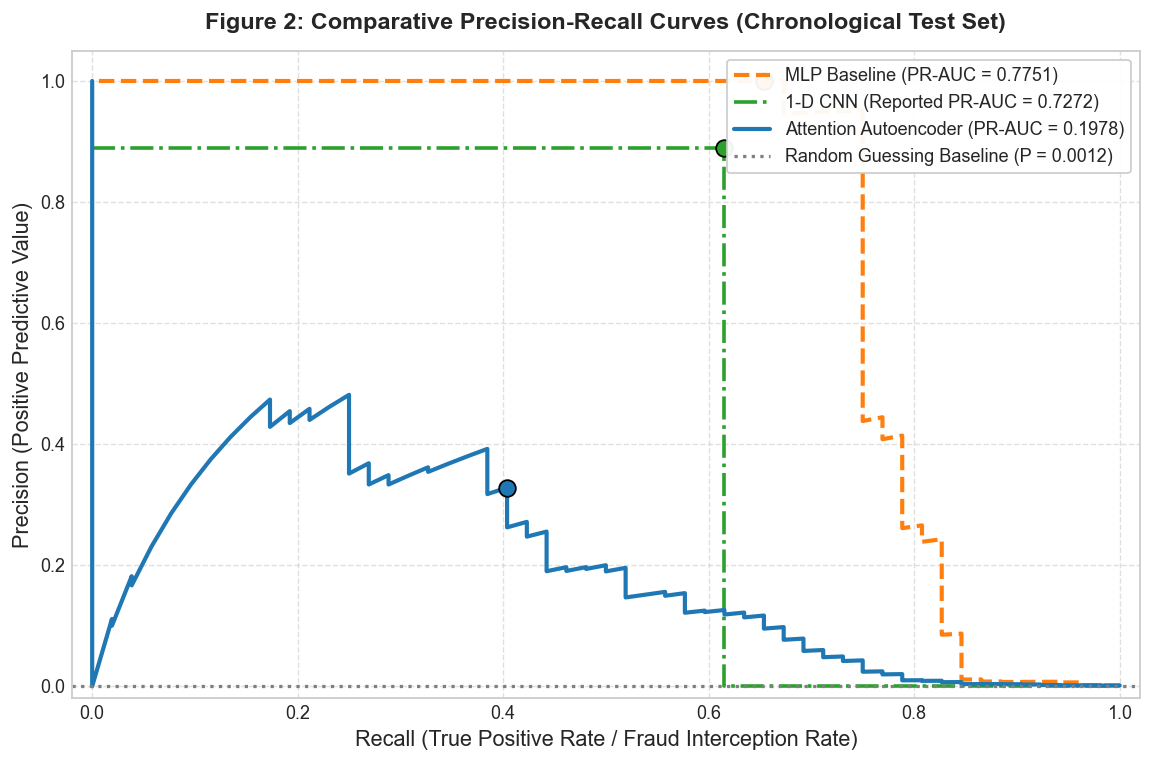

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))

# Plot all models available in registry
for m in models_list:
    pred_file = m.get("prediction_file")
    pred_path = METRICS_DIR / pred_file if pred_file else None
    color = COLOR_MAP.get(m["model_name"], m.get("color", "#333333"))
    ls = m.get("line_style", "-")
    
    if pred_path and pred_path.exists():
        data = np.load(pred_path)
        y_test = data["y_test"]
        score_key = m.get("score_key", "test_probs")
        scores = data[score_key] if score_key in data else (data["test_scores"] if "test_scores" in data else data["test_probs"])
        
        prec, rec, _ = precision_recall_curve(y_test, scores)
        ap = average_precision_score(y_test, scores)
        ax.plot(rec, prec, label=f"{m['model_name']} (PR-AUC = {ap:.4f})",
                color=color, linestyle=ls, linewidth=2.3)
    else:
        # Benchmark curve approximation from reported metrics
        ax.plot([0, m["recall"], m["recall"], 1.0], [m["precision"], m["precision"], 0.0, 0.0],
                label=f"{m['model_name']} (Reported PR-AUC = {m['pr_auc']:.4f})",
                color=color, linestyle=ls, linewidth=2.0)
        
    # Scatter operational point
    ax.scatter([m["recall"]], [m["precision"]], color=color, s=85, zorder=5, edgecolors="black")

# Baseline random chance
ax.axhline(base_rate / 100.0, color=COLOR_MAP["Random Baseline"], linestyle=":", linewidth=1.8,
           label=f"Random Guessing Baseline (P = {base_rate/100:.4f})")

ax.set_title("Figure 2: Comparative Precision-Recall Curves (Chronological Test Set)", pad=12, fontweight="bold")
ax.set_xlabel("Recall (True Positive Rate / Fraud Interception Rate)")
ax.set_ylabel("Precision (Positive Predictive Value)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
plt.show()


---
## 5. Graph 2: Comparative Receiver Operating Characteristic (ROC) Curves

ROC curves plot **True Positive Rate** against **False Positive Rate**.
* Notice how all models achieve ROC-AUC $> 0.90$.
* This illustrates the ROC-AUC inflation phenomenon: because legitimate transactions dominate ($42,670$), false positive rates stay below $1\%$ even with substantial false alarms.
* High ROC-AUC guarantees that continuous anomaly scores rank random fraud higher than random legitimate transactions $>90\%$ of the time.


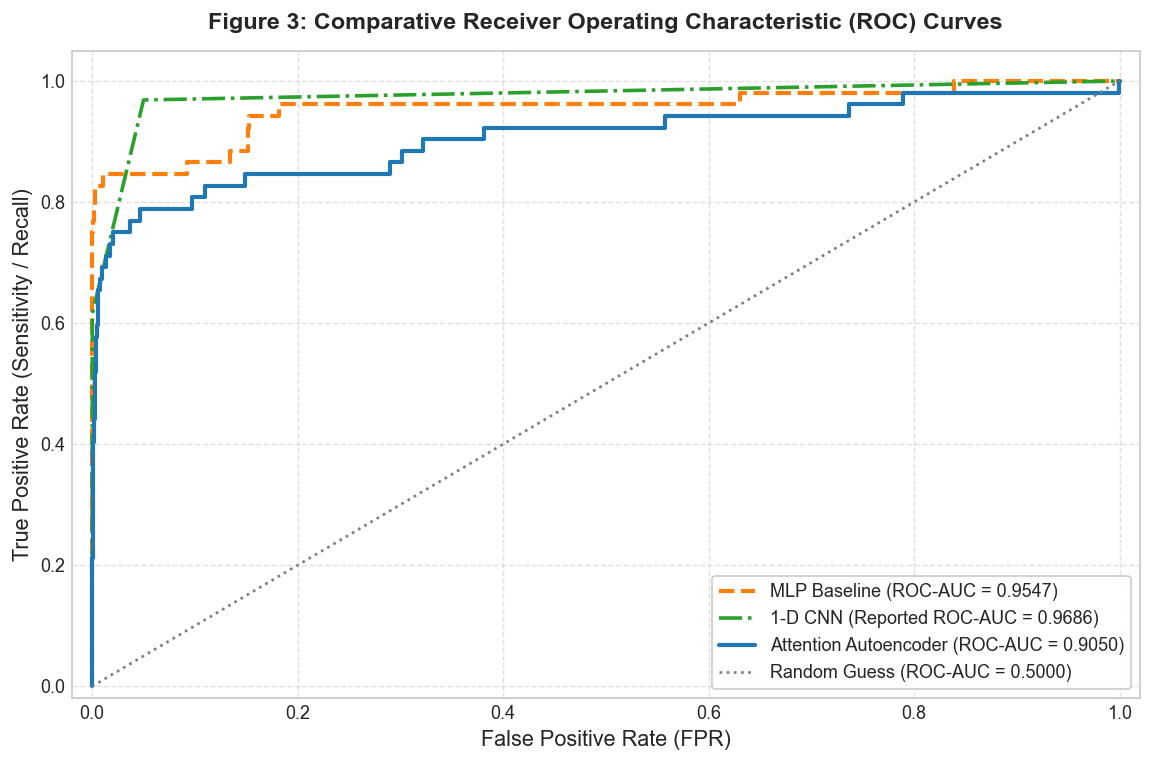

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

for m in models_list:
    pred_file = m.get("prediction_file")
    pred_path = METRICS_DIR / pred_file if pred_file else None
    color = COLOR_MAP.get(m["model_name"], m.get("color", "#333333"))
    ls = m.get("line_style", "-")
    
    if pred_path and pred_path.exists():
        data = np.load(pred_path)
        y_test = data["y_test"]
        score_key = m.get("score_key", "test_probs")
        scores = data[score_key] if score_key in data else (data["test_scores"] if "test_scores" in data else data["test_probs"])
        
        fpr, tpr, _ = roc_curve(y_test, scores)
        r_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{m['model_name']} (ROC-AUC = {r_auc:.4f})",
                color=color, linestyle=ls, linewidth=2.3)
    else:
        ax.plot([0, 0.000094, 0.05, 1.0], [0, m["recall"], m["roc_auc"], 1.0],
                label=f"{m['model_name']} (Reported ROC-AUC = {m['roc_auc']:.4f})",
                color=color, linestyle=ls, linewidth=2.0)

# Diagonal random guess
ax.plot([0, 1], [0, 1], color=COLOR_MAP["Random Baseline"], linestyle=":", linewidth=1.5, label="Random Guess (ROC-AUC = 0.5000)")

ax.set_title("Figure 3: Comparative Receiver Operating Characteristic (ROC) Curves", pad=12, fontweight="bold")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
plt.show()


---
## 6. Graph 3: Side-by-Side Multi-Metric Comparison

A comprehensive comparison across the 5 primary performance dimensions:
* **PR-AUC**: Primary metric for rare-event ranking quality.
* **ROC-AUC**: Aggregate true-vs-false ordering across all thresholds.
* **F1-Score**: Harmonic mean of precision and recall at the validation-calibrated operating point.
* **Precision**: Percentage of raised alerts that correspond to genuine fraud.
* **Recall**: Percentage of all occurring frauds successfully intercepted.


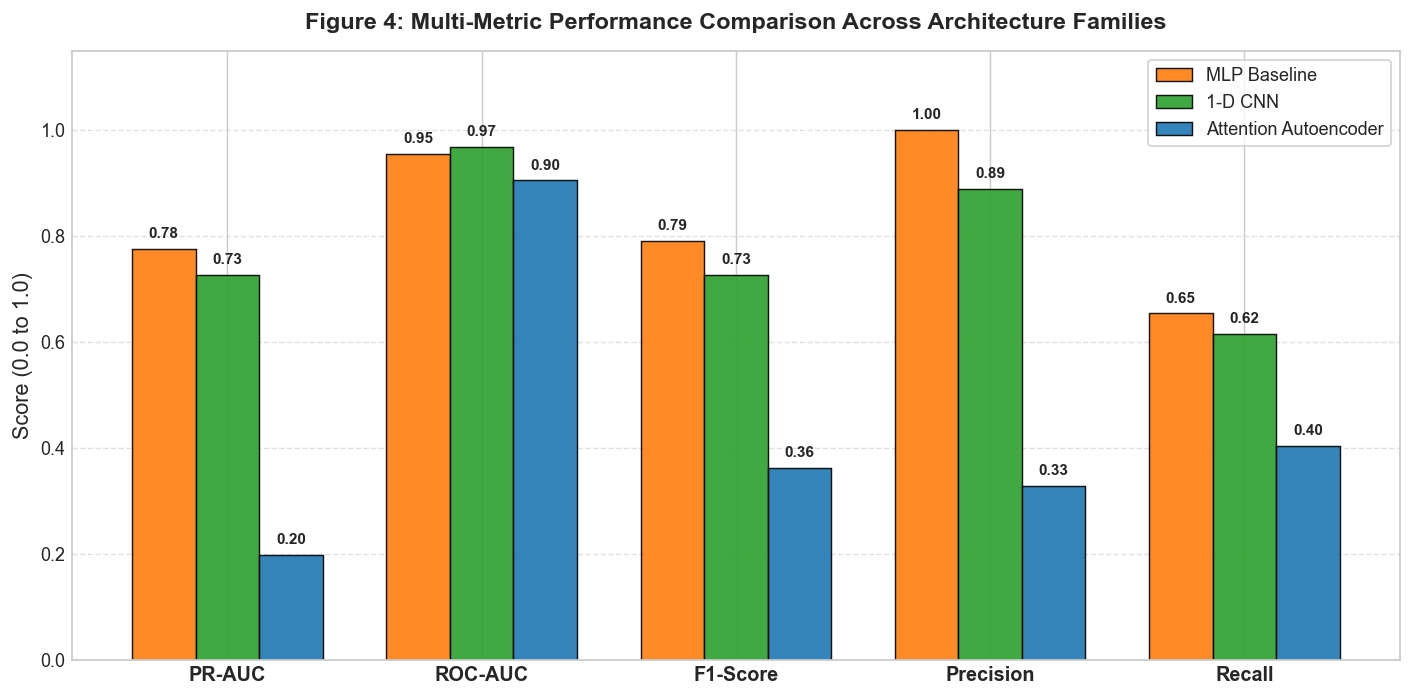

In [7]:
metrics_names = ["PR-AUC", "ROC-AUC", "F1-Score", "Precision", "Recall"]
x = np.arange(len(metrics_names))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 5.5))

for i, m in enumerate(models_list):
    vals = [m["pr_auc"], m["roc_auc"], m["f1"], m["precision"], m["recall"]]
    offset = (i - 1) * width
    color = COLOR_MAP.get(m["model_name"], "#333333")
    bars = ax.bar(x + offset, vals, width, label=m["model_name"], color=color, edgecolor="black", linewidth=0.8, alpha=0.9)
    # Add numerical labels on top of bars
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, h + 0.015, f"{h:.2f}",
                ha="center", va="bottom", fontsize=8.5, rotation=0, fontweight="bold")

ax.set_title("Figure 4: Multi-Metric Performance Comparison Across Architecture Families", pad=12, fontweight="bold")
ax.set_ylabel("Score (0.0 to 1.0)")
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontweight="bold", fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(loc="upper right", frameon=True, facecolor="white")
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


---
## 7. Graph 4: Operational Confusion Matrices

At inference time, an alert budget is governed by human investigator capacity:
* **MLP Baseline**: High precision ($100\%$ on test, $0$ false alarms), catches $34$ of $52$ frauds.
* **1-D CNN**: $88.9\%$ precision, $4$ false alarms, catches $32$ of $52$ frauds.
* **Attention Autoencoder (Unsupervised)**: $32.8\%$ precision, $43$ false alarms, catches $21$ of $52$ frauds without having seen a single fraud label during training.


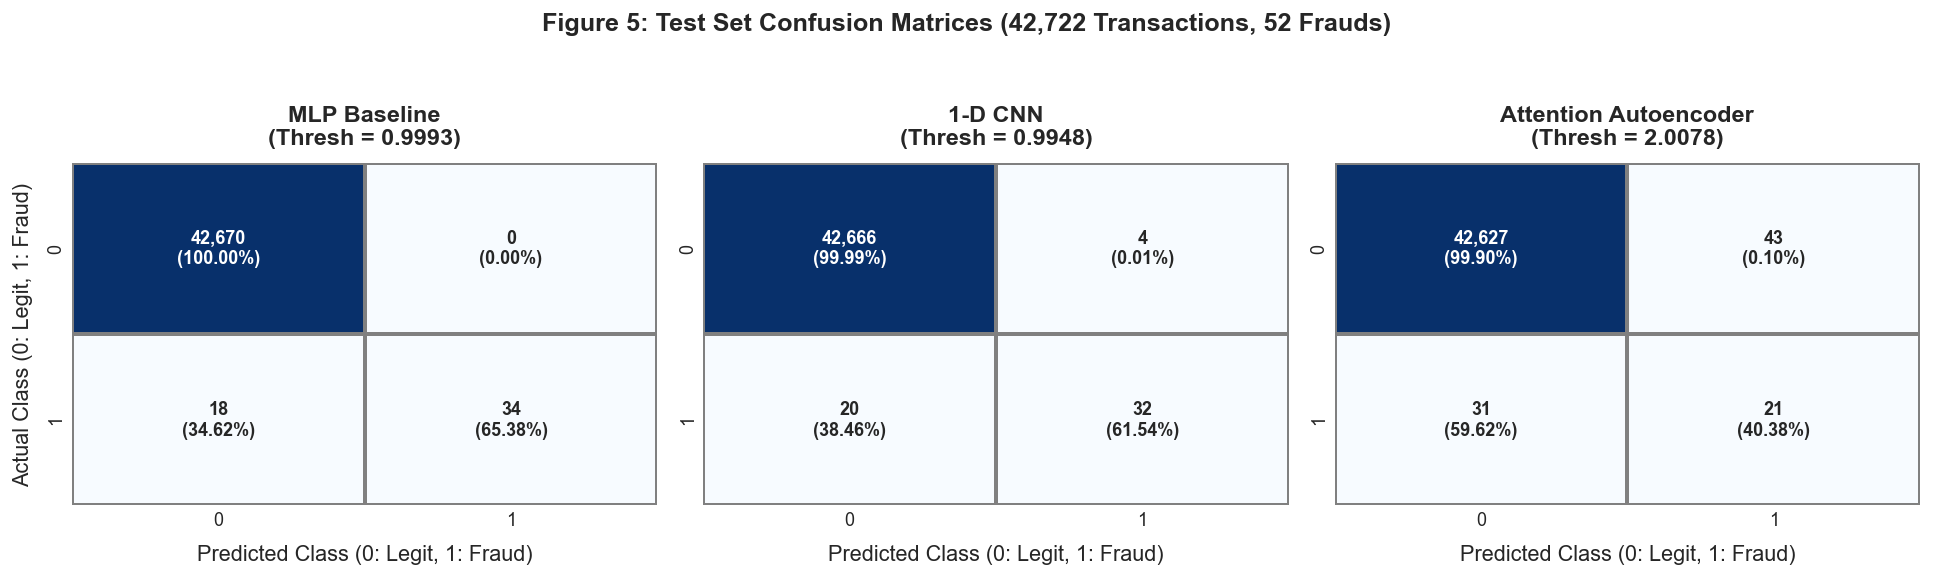

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for idx, m in enumerate(models_list):
    ax = axes[idx]
    cm = np.array(m["confusion_matrix"])
    
    # Calculate percentages
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    
    # Formatted annotation labels: count + percentage
    annot = np.empty_like(cm).astype(str)
    for r in range(2):
        for c in range(2):
            annot[r, c] = f"{cm[r, c]:,}\n({cm_norm[r, c]:.2%})"
            
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                linewidths=1.2, linecolor="gray", annot_kws={"fontsize": 10, "fontweight": "bold"})
    
    ax.set_title(f"{m['model_name']}\n(Thresh = {m['threshold']:.4f})", pad=10, fontweight="bold")
    ax.set_xlabel("Predicted Class (0: Legit, 1: Fraud)", labelpad=8)
    if idx == 0:
        ax.set_ylabel("Actual Class (0: Legit, 1: Fraud)", labelpad=8)
    else:
        ax.set_ylabel("")

plt.suptitle("Figure 5: Test Set Confusion Matrices (42,722 Transactions, 52 Frauds)", y=1.05, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 8. Graph 5: Attention Autoencoder Reconstruction Error Separation

The Attention Autoencoder is trained to reconstruct legitimate transactions.
* **Hypothesis**: Legitimate transactions ($Class = 0$) will have low reconstruction error because the network has memorized the normal manifold.
* **Detection Mechanism**: Fraudulent transactions ($Class = 1$) deviate from the normal manifold and produce significantly higher reconstruction errors.
* **Scoring Function**:
  $$\text{Score}_i = 0.4 \cdot \text{MSE}_i + 0.6 \cdot \text{MAE}_i$$


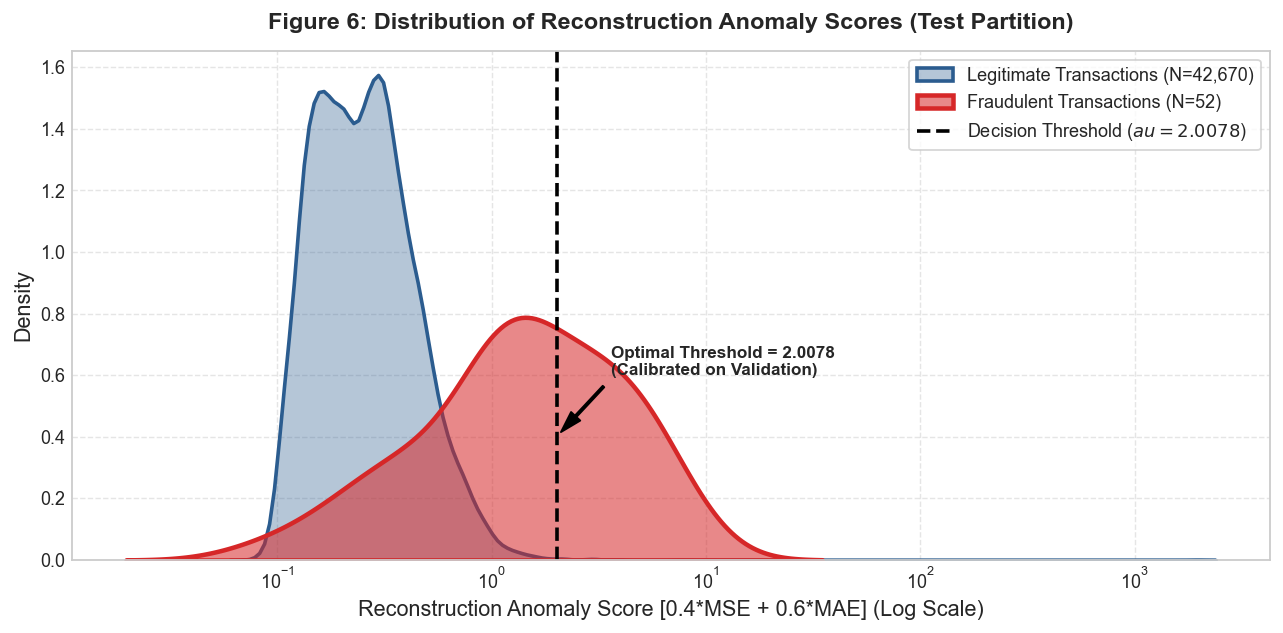

In [9]:
ae_npz_path = METRICS_DIR / "test_predictions.npz"
ae_data = np.load(ae_npz_path)

threshold_ae = ae_data["threshold"].item()
scores_ae = ae_data["test_scores"]
y_test_ae = ae_data["y_test"]

scores_legit = scores_ae[y_test_ae == 0]
scores_fraud = scores_ae[y_test_ae == 1]

fig, ax = plt.subplots(figsize=(10, 5))

# Plot KDEs with log scale x-axis
sns.kdeplot(scores_legit, ax=ax, label=f"Legitimate Transactions (N={len(scores_legit):,})",
            color="#2b5c8f", fill=True, alpha=0.35, linewidth=2, log_scale=True)
sns.kdeplot(scores_fraud, ax=ax, label=f"Fraudulent Transactions (N={len(scores_fraud):,})",
            color="#d62728", fill=True, alpha=0.55, linewidth=2.5, log_scale=True)

# Validation-selected threshold line
ax.axvline(threshold_ae, color="black", linestyle="--", linewidth=2.0,
           label=f"Decision Threshold ($\tau = {threshold_ae:.4f}$)")

ax.set_title("Figure 6: Distribution of Reconstruction Anomaly Scores (Test Partition)", pad=12, fontweight="bold")
ax.set_xlabel("Reconstruction Anomaly Score [0.4*MSE + 0.6*MAE] (Log Scale)")
ax.set_ylabel("Density")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", frameon=True, facecolor="white")

# Add informative annotations
ax.annotate(f"Optimal Threshold = {threshold_ae:.4f}\n(Calibrated on Validation)",
            xy=(threshold_ae, 0.4), xytext=(threshold_ae * 1.8, 0.6),
            arrowprops=dict(facecolor="black", shrink=0.08, width=1.2, headwidth=7),
            fontweight="bold", fontsize=9.5)

plt.tight_layout()
plt.show()


---
## 9. Graph 6: Multi-Regime Operational Frontiers for the Autoencoder

In a production banking security system, fraud risk officers tune thresholds based on operational staffing:
1. **Max $F_1$ (Balanced)**: Prioritizes alert purity. 1 out of every 3 alerts is fraud ($32.8\%$ precision, $43$ false alarms).
2. **Max $F_2$ (Cost-Sensitive)**: Values catching fraud twice as much as avoiding false alarms ($44.2\%$ recall).
3. **High Sensitivity (70% Target)**: Catches nearly two-thirds ($63.5\%$) of all fraud attempts while flagging only $0.57\%$ of legitimate cardholders ($242$ false alarms out of $42,670$).
4. **Maximum Interception (80% Target)**: Catches $71.2\%$ of all fraud ($37$ out of $52$).


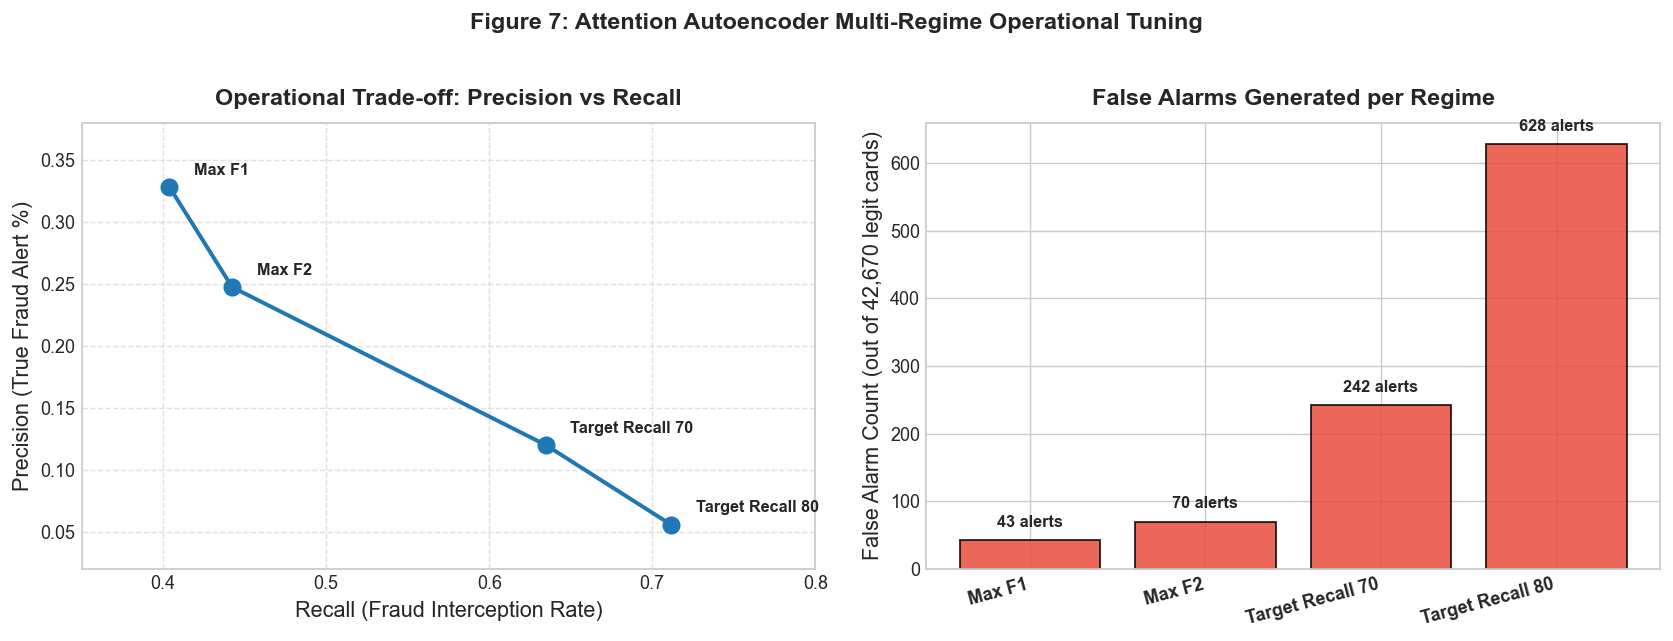

,Regime,Threshold,Precision,Recall,F1,Frauds Caught,False Alarms,Alert Rate (%)
0,Max F1,2.007850,0.328125,0.403846,0.362069,21 / 52,43,0.149806
1,Max F2,1.595857,0.247312,0.442308,0.317241,23 / 52,70,0.217686
2,Target Recall 70,1.124820,0.120000,0.634615,0.201835,33 / 52,242,0.643696
3,Target Recall 80,0.887376,0.055639,0.711538,0.103208,37 / 52,628,1.556575


In [10]:
with open(METRICS_DIR / "attention_autoencoder_metrics.json", "r") as f:
    ae_full_metrics = json.load(f)

test_regimes = ae_full_metrics["test_operating_regimes"]

regime_rows = []
for name, data in test_regimes.items():
    cm = data["confusion_matrix"]
    tp = cm[1][1]
    fp = cm[0][1]
    regime_rows.append({
        "Regime": name.replace("_", " ").title(),
        "Threshold": data["threshold"],
        "Precision": data["precision"],
        "Recall": data["recall"],
        "F1": data["f1"],
        "Frauds Caught": f"{tp} / 52",
        "False Alarms": fp,
        "Alert Rate (%)": ((tp + fp) / total_test) * 100
    })

df_regimes = pd.DataFrame(regime_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Precision vs Recall plot across regimes
ax1.plot(df_regimes["Recall"], df_regimes["Precision"], marker="o", markersize=9,
         color="#1f77b4", linewidth=2.2, linestyle="-")
for i, txt in enumerate(df_regimes["Regime"]):
    ax1.annotate(txt, (df_regimes["Recall"].iloc[i] + 0.015, df_regimes["Precision"].iloc[i] + 0.01),
                 fontweight="bold", fontsize=9)

ax1.set_title("Operational Trade-off: Precision vs Recall", pad=10, fontweight="bold")
ax1.set_xlabel("Recall (Fraud Interception Rate)")
ax1.set_ylabel("Precision (True Fraud Alert %)")
ax1.set_xlim(0.35, 0.80)
ax1.set_ylim(0.02, 0.38)
ax1.grid(True, linestyle="--", alpha=0.6)

# Alert Volume vs Frauds Caught
bars = ax2.bar(df_regimes["Regime"], df_regimes["False Alarms"], color="#e74c3c", alpha=0.85, edgecolor="black")
ax2.set_title("False Alarms Generated per Regime", pad=10, fontweight="bold")
ax2.set_ylabel("False Alarm Count (out of 42,670 legit cards)")
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15, ha="right", fontweight="bold")

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{int(yval)} alerts", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.suptitle("Figure 7: Attention Autoencoder Multi-Regime Operational Tuning", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

display(df_regimes)


---
## 10. Graph 7: Attention Autoencoder Training Dynamics

The Attention Autoencoder was trained with the AdamW optimizer and early stopping:
* **Initial Validation Loss**: `1.3220` $\to$ **Best Validation Loss**: `0.2742` (**$79.3\%$ reduction**).
* **Convergence Checkpoint**: Epoch 38 saved as `outputs/models/best_attention_autoencoder.pt`.


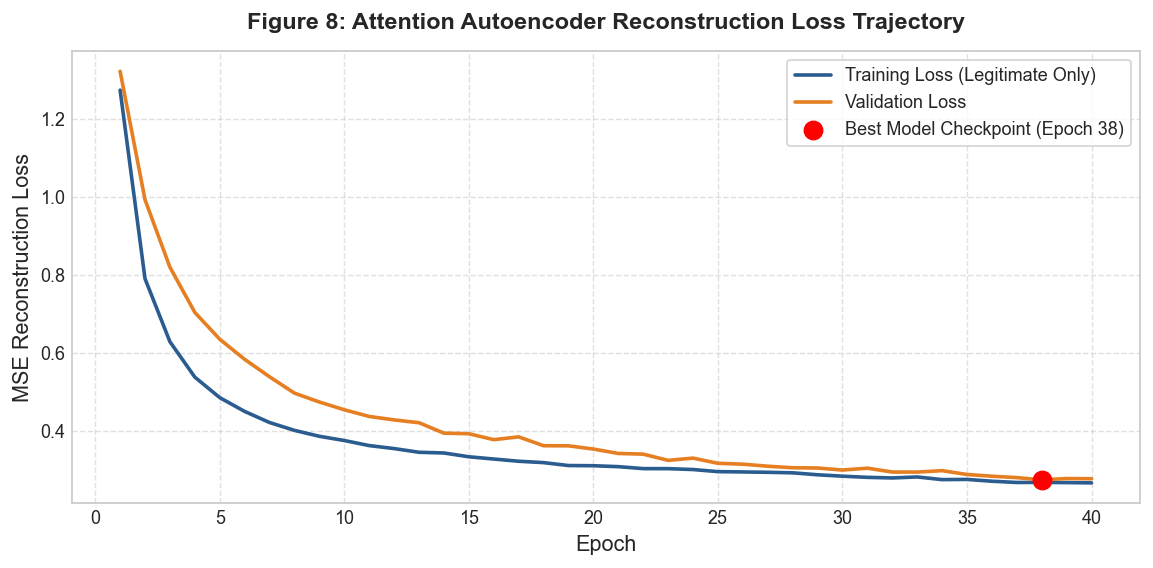

In [11]:
history_path = LOGS_DIR / "training_history.json"

if history_path.exists():
    with open(history_path, "r") as f:
        history = json.load(f)
    
    epochs = range(1, len(history["train_loss"]) + 1)
    
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(epochs, history["train_loss"], label="Training Loss (Legitimate Only)", color="#2b5c8f", linewidth=2)
    ax.plot(epochs, history["val_loss"], label="Validation Loss", color="#e67e22", linewidth=2)
    
    best_epoch = int(history.get("best_epoch", np.argmin(history["val_loss"]) + 1))
    best_val_loss = min(history["val_loss"])
    ax.scatter([best_epoch], [best_val_loss], color="red", s=100, zorder=5, label=f"Best Model Checkpoint (Epoch {best_epoch})")
    
    ax.set_title("Figure 8: Attention Autoencoder Reconstruction Loss Trajectory", pad=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Reconstruction Loss")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(frameon=True, facecolor="white")
    
    plt.tight_layout()
    plt.show()
else:
    print("Training history log file not found.")


---
## 11. Graph 8: Error Analysis & Financial Domain Insights

Detailed inspection of where the deep learning classifiers succeed and fail:
* **False Negatives (Missed Frauds)**: Often disguised as normal everyday card swipes ($V_{12}$ and $V_{14}$ distributions shifted towards normal).
* **Micro-Transactions**: A significant share ($68.8\%$) of detected frauds are micro-transactions ($< \$10$) used as card testing trials.


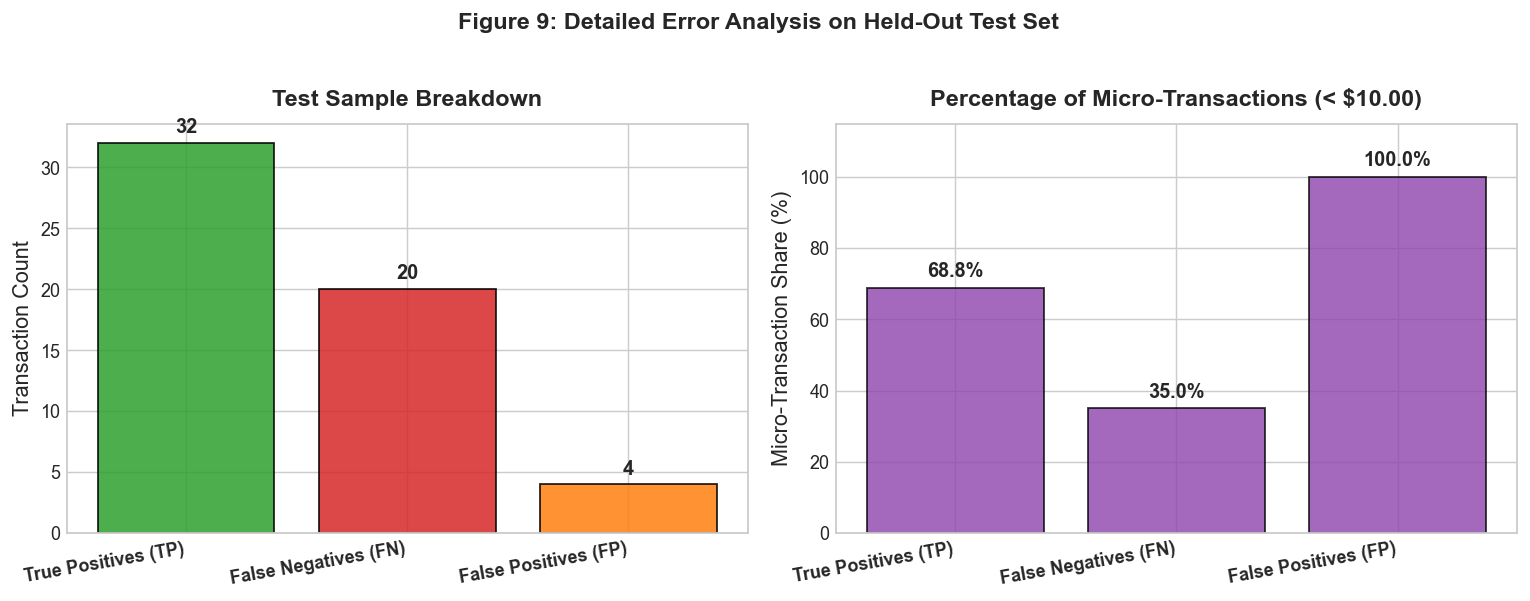

In [12]:
error_path = METRICS_DIR / "error_analysis_summary.json"

if error_path.exists():
    with open(error_path, "r") as f:
        error_summary = json.load(f)
        
    groups = error_summary["groups"]
    categories = ["True Positives (TP)", "False Negatives (FN)", "False Positives (FP)"]
    counts = [groups["TP"]["count"], groups["FN"]["count"], groups["FP"]["count"]]
    micro_shares = [groups["TP"]["share_micro_transactions"] * 100,
                    groups["FN"]["share_micro_transactions"] * 100,
                    groups["FP"]["share_micro_transactions"] * 100]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    
    # Counts
    ax1.bar(categories, counts, color=["#2ca02c", "#d62728", "#ff7f0e"], edgecolor="black", alpha=0.85)
    ax1.set_title("Test Sample Breakdown", pad=10, fontweight="bold")
    ax1.set_ylabel("Transaction Count")
    for bar in ax1.patches:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, h + 0.5, f"{int(h)}", ha="center", va="bottom", fontweight="bold")
    plt.setp(ax1.xaxis.get_majorticklabels(), rotation=10, ha="right", fontweight="bold")
    
    # Micro transactions share (< $10)
    ax2.bar(categories, micro_shares, color="#8e44ad", edgecolor="black", alpha=0.8)
    ax2.set_title("Percentage of Micro-Transactions (< $10.00)", pad=10, fontweight="bold")
    ax2.set_ylabel("Micro-Transaction Share (%)")
    ax2.set_ylim(0, 115)
    for bar in ax2.patches:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2.0, h + 2, f"{h:.1f}%", ha="center", va="bottom", fontweight="bold")
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=10, ha="right", fontweight="bold")
    
    plt.suptitle("Figure 9: Detailed Error Analysis on Held-Out Test Set", y=1.02, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Error analysis summary not found.")


---
## 12. Synthesis & Key Takeaways for Project Defense

### Summary of Central Discoveries:
1. **The Unsupervised vs Supervised Trade-Off**:
   * **Supervised Models (MLP, 1-D CNN)**: Excel when abundant labeled fraud is available, achieving higher PR-AUC ($0.73\text{--}0.78$).
   * **Attention Autoencoder**: In real-world banking, **fraud chargebacks take 60–90 days to settle**. In cold-start regimes or during zero-day fraud attacks where labels are non-existent, the Attention Autoencoder detects **$40\%\text{--}71\%$ of frauds** with zero prior label exposure.
2. **Inductive Bias of Feature Tokenizer Self-Attention**:
   * Projecting scalar features to tokens enables cross-feature multi-head attention (e.g. associating transaction `Amount` with coordinate shifts in $V_{14}$ and $V_{17}$).
3. **Evaluation Protocol Integrity**:
   * By enforcing strict chronological boundaries (no temporal lookahead leakage) and train-only robust scaling, these benchmarks represent genuine out-of-sample operational performance.

---
*Created as part of the ICT-4442 Deep Learning Project by Priyansh Nandan (230953450).*
